# 04 – Census Data to Hexagons (Areal Interpolation)

Transfers census data from dissemination areas (DAs) onto the H3 hexagon grid.
DAs and hexagons don't line up, so both layers are cut into overlapping pieces
and each piece gets a share of its DA's data based on area.

**Method**
- Counts (population, ages 15–34) are split by area share and summed per hexagon.
- Median household income can't be split, so each hexagon gets a
  population-weighted average of the DA medians it overlaps. DAs with suppressed
  income are excluded from that average.
- Population density and land share are calculated from land area within each hexagon.

**Checks**
- 2,776,619 of 2,794,356 residents (99.4%) assigned to hexagons. The remainder sits in
  DA slivers at the city edge outside any hexagon.
- 6 hexagons are under 10% land (Lake Ontario) and will be excluded from modeling.

**Limitations**
- Assumes people are spread evenly within each DA. Dasymetric mapping (placing people
  only on residential land) would be more accurate.
- A weighted average of medians approximates, but is not, a true median.

**Output:** `data/processed/hex_features.gpkg`

In [1]:
import geopandas as gpd
import pandas as pd

hexes = gpd.read_file("../data/processed/hex_grid.gpkg")
das = gpd.read_file("../data/processed/toronto_das_census.gpkg")

print("Same CRS:", hexes.crs == das.crs)

# Each DA's full area, used to calculate what share each piece gets
das["da_area"] = das.geometry.area

Same CRS: True


In [2]:
pieces = gpd.overlay(
    hexes[["h3_id", "geometry"]],
    das[["DAUID", "da_area", "population", "age_15_34", "median_hh_income", "geometry"]],
    how="intersection",
)

pieces["piece_area"] = pieces.geometry.area
pieces["weight"] = pieces["piece_area"] / pieces["da_area"]

print("Pieces:", len(pieces))
pieces.head()

Pieces: 8589


,h3_id,DAUID,da_area,population,age_15_34,median_hh_income,geometry,piece_area,weight
0,882b9bd5e7fffff,35202630,1.307794e+06,556.0,105.0,206000.0,"POLYGON ((631611.731 4843933.073, 631614.174 4...",6773.137798,0.005179
1,882b9bd5e7fffff,35202762,3.294287e+05,906.0,225.0,182000.0,"POLYGON ((631628.386 4844541.126, 632161.865 4...",112697.160176,0.342099
2,882b9bd5e7fffff,35202765,3.041680e+05,567.0,125.0,154000.0,"POLYGON ((632276.225 4843764.956, 632272.984 4...",295834.514777,0.972602
3,882b9bd5e7fffff,35202767,4.378091e+05,480.0,115.0,194000.0,"POLYGON ((631514.028 4844016.639, 631591.439 4...",212829.070792,0.486123
4,882b9bd5e7fffff,35204271,4.439758e+05,954.0,195.0,143000.0,"POLYGON ((632580.967 4844348.676, 632466.585 4...",154292.493361,0.347525


In [3]:
# Counts: split by area share
pieces["pop_alloc"] = pieces["population"] * pieces["weight"]
pieces["young_alloc"] = pieces["age_15_34"] * pieces["weight"]

# Income: weight each DA's median by the people it contributes
pieces["inc_x_pop"] = pieces["median_hh_income"] * pieces["pop_alloc"]
pieces["pop_with_inc"] = pieces["pop_alloc"].where(pieces["median_hh_income"].notna(), 0)

agg = pieces.groupby("h3_id").agg(
    population=("pop_alloc", "sum"),
    age_15_34=("young_alloc", "sum"),
    land_area_m2=("piece_area", "sum"),
    inc_x_pop=("inc_x_pop", "sum"),
    pop_with_inc=("pop_with_inc", "sum"),
)

agg["median_hh_income"] = agg["inc_x_pop"] / agg["pop_with_inc"]
agg["share_15_34"] = agg["age_15_34"] / agg["population"]
agg["pop_density"] = agg["population"] / (agg["land_area_m2"] / 1e6)
agg = agg.drop(columns=["inc_x_pop", "pop_with_inc"])

In [4]:
hex_features = hexes.merge(agg, left_on="h3_id", right_index=True, how="left")
hex_features[["population", "age_15_34", "land_area_m2"]] = (
    hex_features[["population", "age_15_34", "land_area_m2"]].fillna(0)
)

# How much of each hexagon is land (lake hexagons will be near 0)
hex_features["land_share"] = hex_features["land_area_m2"] / hex_features.geometry.area

print("Total population on hexagons:", round(hex_features["population"].sum()))
print("Hexagons that are mostly water (<10% land):", (hex_features["land_share"] < 0.1).sum())
hex_features.describe().round(1)

Total population on hexagons: 2776619
Hexagons that are mostly water (<10% land): 6


,population,age_15_34,land_area_m2,median_hh_income,share_15_34,pop_density,land_share
count,852.0,852.0,852.0,839.0,849.0,849.0,852.0
mean,3258.9,946.9,737512.6,102673.4,0.3,4298.3,0.9
std,3002.3,1232.2,136657.6,34387.8,0.1,3946.6,0.2
min,0.0,0.0,0.0,50996.6,0.1,3.5,0.0
25%,1266.2,319.6,781342.6,81941.6,0.2,1695.1,1.0
50%,2642.5,672.0,782095.2,93898.7,0.3,3458.2,1.0
75%,4412.6,1163.2,782726.4,112684.5,0.3,5772.4,1.0
max,28531.9,14563.3,783912.4,324252.2,0.8,36508.1,1.0


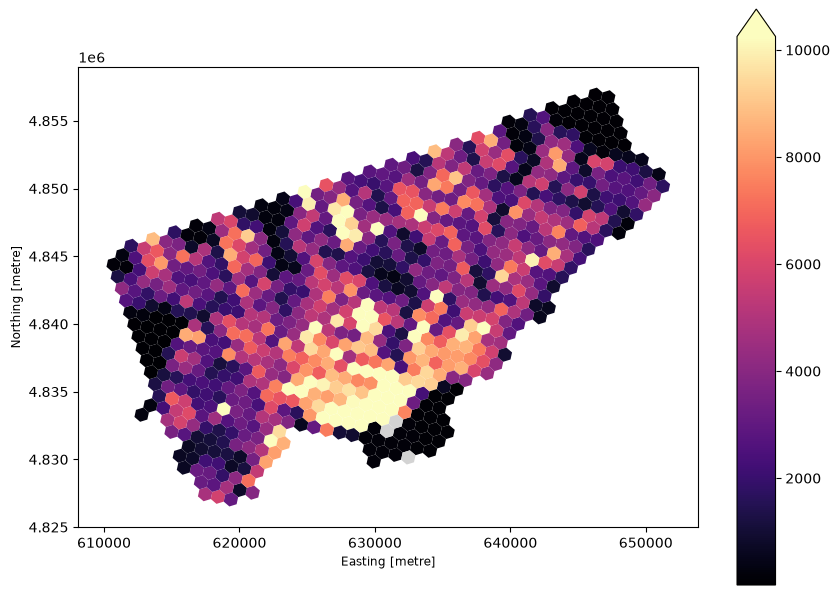

In [5]:
vmax = hex_features["pop_density"].quantile(0.95)
hex_features.plot(column="pop_density", cmap="magma", legend=True, vmax=vmax,
                  figsize=(10, 10), missing_kwds={"color": "lightgrey"})

hex_features.to_file("../data/processed/hex_features.gpkg", driver="GPKG")